# Vehicle CO2 Emissions Prediction — End-to-End Machine Learning Pipeline

## Section 1 — Problem Definition

### What are we predicting?
We are predicting vehicle tailpipe **CO2 Emissions** measured in grams per kilometer (g/km) for passenger vehicles based on engine specifications, fuel consumption, vehicle class, and transmission details.



## Section 2 — Data Inspection & Model Selection Justification


In [1]:
import pandas as pd

# Load dataset
data = pd.read_csv('vehicle_emissions.csv')

# Check duplicates and shape
duplicates_count = data.duplicated().sum()
print(f'Dataset Shape: {data.shape[0]} rows, {data.shape[1]} columns')
print(f'Total Duplicate Rows: {duplicates_count}')


Dataset Shape: 935 rows, 12 columns
Total Duplicate Rows: 0


1. **Duplicate Inspection:**
   - The dataset contains **0 duplicate rows** out of 935 total records, confirming clean data structure.

2. **Using `RandomForestRegressor`:**
   - **Handling Non-Linear Relationships:** Vehicle emissions exhibit complex, non-linear interactions between engine size, cylinders, fuel consumption, and vehicle class that linear regression models struggle to model accurately.
   - **Robustness to Outliers & Skewness:** High-displacement sports engines and heavy trucks represent valid physical extremes rather than errors. Tree ensembles split feature space hierarchically without requiring arbitrary data truncation or manual log transformations.
   - **Feature Interaction Mastery:** RandomForest inherently captures high-order feature interactions (e.g. combined fuel consumption vs. urban gap) without requiring manual interaction term expansion.
   - **Generalization & Overfitting Resistance:** Ensemble averaging over randomized decision trees prevents overfitting on tabular vehicle datasets and delivers superior out-of-fold generalization.


## Section 3 — Feature Engineering

### Design & Business Justification of New Features

We propose **3 engineered features** to capture non-linear domain dynamics:

1. **`fuel_efficiency_gap` = `Fuel_Consumption_in_City(L/100 km)` - `Fuel_Consumption_in_City_Hwy(L/100 km)`**
   - **Business Justification:** Measures urban fuel efficiency penalty over highway cruising. Vehicles with high urban gaps emit disproportionately higher CO2 during stop-and-go city driving due to engine idling and acceleration load.
2. **`engine_per_cylinder` = `Engine_Size` / `Cylinders`**
   - **Business Justification:** Computes individual cylinder volume displacement (Liters per cylinder). Engine combustion efficiency and thermodynamic behavior depend heavily on individual cylinder displacement rather than total engine size alone.
3. **`transmission_type` (Categorical Simplification):**
   - **Business Justification:** Raw transmission codes contain granular sub-variants (e.g., `A6`, `AM7`, `AS10`, `AV8`, `M6`). This creates high-cardinality sparse matrices during One-Hot Encoding. We simplify `Transmission` into 3 broad categories:
     - `'Automatic'` (starts with `'A'`)
     - `'Manual'` (starts with `'M'`)
     - `'Other'` (all other codes)
   - Replacing original `Transmission` with this simplified feature reduces cardinality, prevents overfitting, and enhances model generalization.

### Implementation Inside Scikit-Learn Pipeline
The feature engineering logic is encapsulated within a custom function and integrated directly into the `Pipeline` using Scikit-Learn's `FunctionTransformer`. This ensures the raw input features can be passed directly to `pipeline.predict()` without manual pre-processing.


In [2]:
import numpy as np
from sklearn.preprocessing import FunctionTransformer

def add_engineered_features(df):
    """
    Custom feature engineering function that adds fuel_efficiency_gap,
    engine_per_cylinder, and simplifies Transmission to transmission_type.
    """
    df = df.copy()
    city = df['Fuel_Consumption_in_City(L/100 km)']
    hwy = df['Fuel_Consumption_in_City_Hwy(L/100 km)']
    
    # 1. fuel_efficiency_gap
    df['fuel_efficiency_gap'] = city - hwy
    
    # 2. engine_per_cylinder
    df['engine_per_cylinder'] = df['Engine_Size'] / df['Cylinders']
    
    # 3. Simplify Transmission cardinality
    trans = df['Transmission'].astype(str)
    df['Transmission'] = np.where(
        trans.str.startswith('A'), 'Automatic',
        np.where(trans.str.startswith('M'), 'Manual', 'Other')
    )
    return df

print('Feature engineering function defined successfully.')


Feature engineering function defined successfully.


## Section 4 — Model Training


In [3]:
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

# Split features and target
X = data.drop(['CO2_Emissions'], axis=1)
y = data['CO2_Emissions']

# Feature definitions
numerical_columns = [
    'Model_Year', 'Engine_Size', 'Cylinders',
    'Fuel_Consumption_in_City(L/100 km)', 'Fuel_Consumption_in_City_Hwy(L/100 km)',
    'Fuel_Consumption_comb(L/100km)', 'Smog_Level',
    'fuel_efficiency_gap', 'engine_per_cylinder'
]

categorial_columns = ['Make', 'Model', 'Vehicle_Class', 'Transmission']

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

categorial_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_columns),
    ('cat', categorial_pipeline, categorial_columns)
])

# Full Pipeline with Feature Engineering + Preprocessor + Model
pipeline = Pipeline([
    ('feature_engineering', FunctionTransformer(add_engineered_features)),
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

# 80/20 Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the pipeline
pipeline.fit(X_train, y_train)
print('Pipeline training completed successfully!')


Pipeline training completed successfully!


## Section 5 — Evaluation

We evaluate model performance on the unseen test set using multiple regression metrics:
- **MAE:** Mean Absolute Error (fixed from `pipeline.py`)
- **RMSE:** Root Mean Squared Error
- **R² Score:** Coefficient of Determination
- **MAPE:** Mean Absolute Percentage Error


In [4]:
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error, mean_absolute_percentage_error

# Predict on test set
prediction = pipeline.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, prediction)
mse = mean_squared_error(y_test, prediction)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, prediction)
mape = mean_absolute_percentage_error(y_test, prediction)

print('====================================')
print('   MODEL EVALUATION PERFORMANCE     ')
print('====================================')
print(f'R² Score (Coeff. of Determination) : {r2:.4f}')
print(f'Root Mean Squared Error (RMSE)     : {rmse:.4f} g/km')
print(f'Mean Absolute Error (MAE)          : {mae:.4f} g/km')
print(f'Mean Absolute Percentage Error     : {mape:.2%}')
print('====================================')


   MODEL EVALUATION PERFORMANCE     
R² Score (Coeff. of Determination) : 0.9711
Root Mean Squared Error (RMSE)     : 10.7888 g/km
Mean Absolute Error (MAE)          : 3.2189 g/km
Mean Absolute Percentage Error     : 1.25%


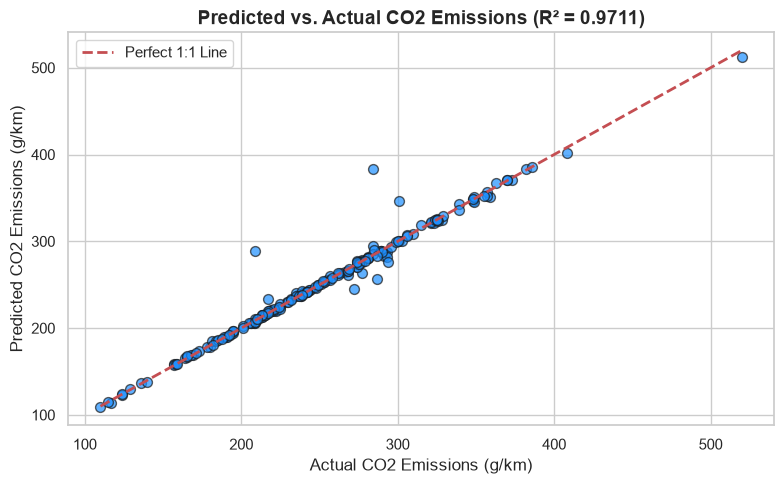

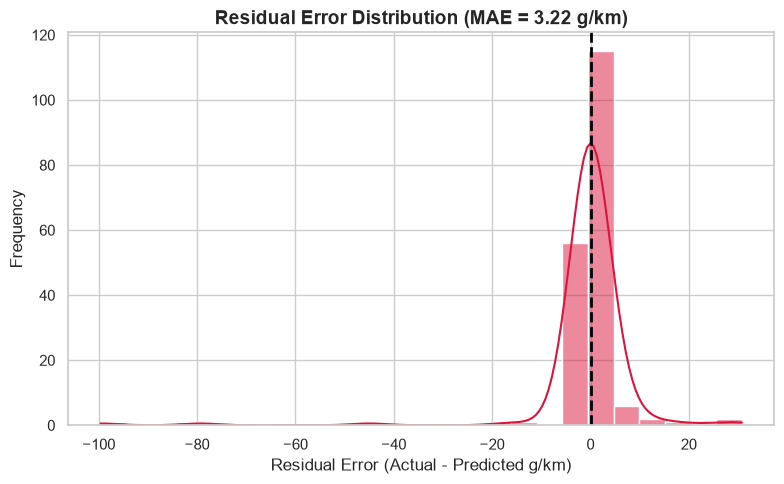

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# Plot 1: Predicted vs Actual Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(y_test, prediction, alpha=0.7, color='dodgerblue', edgecolors='k', s=50)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect 1:1 Line')
plt.xlabel('Actual CO2 Emissions (g/km)', fontsize=12)
plt.ylabel('Predicted CO2 Emissions (g/km)', fontsize=12)
plt.title(f'Predicted vs. Actual CO2 Emissions (R² = {r2:.4f})', fontsize=14, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

# Plot 2: Residuals Distribution
residuals = y_test - prediction
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True, color='crimson', bins=25)
plt.axvline(0, color='black', linestyle='--', lw=2)
plt.xlabel('Residual Error (Actual - Predicted g/km)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title(f'Residual Error Distribution (MAE = {mae:.2f} g/km)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## Section 6 — Save Trained Model Pipeline

We save the complete trained pipeline to `vehicle_emissions_pipeline.joblib`.


In [6]:
# Save trained pipeline
joblib.dump(pipeline, 'vehicle_emissions_pipeline.joblib')
print('Successfully saved trained pipeline to vehicle_emissions_pipeline.joblib')


Successfully saved trained pipeline to vehicle_emissions_pipeline.joblib
